### 02 — Data Preparation and Train/Validation/Test Split
Goal
Load the manifest created by Notebook 01, validate data integrity, inspect class balance, create reproducible 70/15/15 splits, verify no overlap or lost samples, and export split CSVs plus a JSON report.

Important: do not balance or augment the complete dataset before splitting. Keep validation and test data representative of the original dataset. If several images belong to one patient, populate PATIENT_COL and use patient-level splitting to prevent leakage. This notebook's default path uses stratified image-level splitting only when no patient ID is available.

For YOLO detection, keep annotation references/columns in the manifest and ensure the split procedure operates on images or patients—not individual bounding boxes.

In [10]:
from pathlib import Path
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from IPython.display import display

RANDOM_STATE = 42
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Change these if your paths differ.
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "manifest.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "splits"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_COL = "image_path"
LABEL_COL = "label"
# Set to the actual manifest column (e.g. "patient_id") if available; else None.
PATIENT_COL = None

assert np.isclose(TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO, 1.0), "Split ratios must sum to 1."
print("Project root:", PROJECT_ROOT)
print("Manifest:", MANIFEST_PATH)
print("Output:", OUTPUT_DIR)


Project root: /home/moali/projects/brainscan_ai
Manifest: /home/moali/projects/brainscan_ai/data/processed/manifest.csv
Output: /home/moali/projects/brainscan_ai/data/splits


### 2. Load and inspect the manifest

In [11]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}. Run Notebook 01 first or update MANIFEST_PATH."
    )

df = pd.read_csv(MANIFEST_PATH)
if df.empty:
    raise ValueError("Manifest is empty.")

print(f"Rows: {len(df):,}")
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("dtype"))

required_columns = [IMAGE_COL, LABEL_COL] + ([PATIENT_COL] if PATIENT_COL else [])
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}. Available: {df.columns.tolist()}")


Rows: 7,023
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']


,image_path,relative_path,label,extension,file_size_bytes,width,height,image_mode,is_valid
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0000.jpg,glioma,.jpg,25826,512,512,RGB,True
1,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0001.jpg,glioma,.jpg,20982,512,512,RGB,True
2,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0002.jpg,glioma,.jpg,13285,512,512,RGB,True
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0003.jpg,glioma,.jpg,26137,512,512,RGB,True
4,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0004.jpg,glioma,.jpg,21709,512,512,RGB,True


,dtype
image_path,str
relative_path,str
label,str
extension,str
file_size_bytes,int64
width,int64
height,int64
image_mode,str
is_valid,bool


### 3. Validate paths, labels, and duplicates

In [12]:
# Strip whitespace but do not silently drop records.
df[IMAGE_COL] = df[IMAGE_COL].astype("string").str.strip()
df[LABEL_COL] = df[LABEL_COL].astype("string").str.strip()

empty_path = df[IMAGE_COL].isna() | df[IMAGE_COL].eq("")
empty_label = df[LABEL_COL].isna() | df[LABEL_COL].eq("")
print("Empty paths:", int(empty_path.sum()))
print("Empty labels:", int(empty_label.sum()))

if empty_path.any() or empty_label.any():
    display(df.loc[empty_path | empty_label])
    raise ValueError("Empty image paths or labels detected. Fix the manifest before splitting.")

# Normalize path strings for duplicate checking.
def resolve_path(value):
    p = Path(str(value)).expanduser()
    if p.is_absolute():
        return p.resolve()
    return (PROJECT_ROOT / p).resolve()

df["_resolved_path"] = df[IMAGE_COL].map(resolve_path)
df["_normalized_path"] = df["_resolved_path"].astype(str)

duplicate_mask = df["_normalized_path"].duplicated(keep=False)
print("Rows participating in duplicate paths:", int(duplicate_mask.sum()))
if duplicate_mask.any():
    display(df.loc[duplicate_mask, [IMAGE_COL, LABEL_COL]].sort_values(IMAGE_COL).head(30))
    raise ValueError("Duplicate image paths found. Resolve duplicates before splitting.")

missing_file_mask = ~df["_resolved_path"].map(Path.is_file)
print("Missing image files:", int(missing_file_mask.sum()))
if missing_file_mask.any():
    display(df.loc[missing_file_mask, [IMAGE_COL, LABEL_COL]].head(30))
    raise FileNotFoundError("Some manifest image files do not exist. Fix paths before splitting.")

if df[LABEL_COL].nunique() < 2:
    raise ValueError("At least two classes are needed for stratified classification splitting.")

print("Path and label checks passed.")


Empty paths: 0
Empty labels: 0
Rows participating in duplicate paths: 0
Missing image files: 0
Path and label checks passed.


### 4. Analyze the original class balance

,image_count,percentage
label,,
glioma,1621,23.08
meningioma,1645,23.42
notumor,2000,28.48
pituitary,1757,25.02


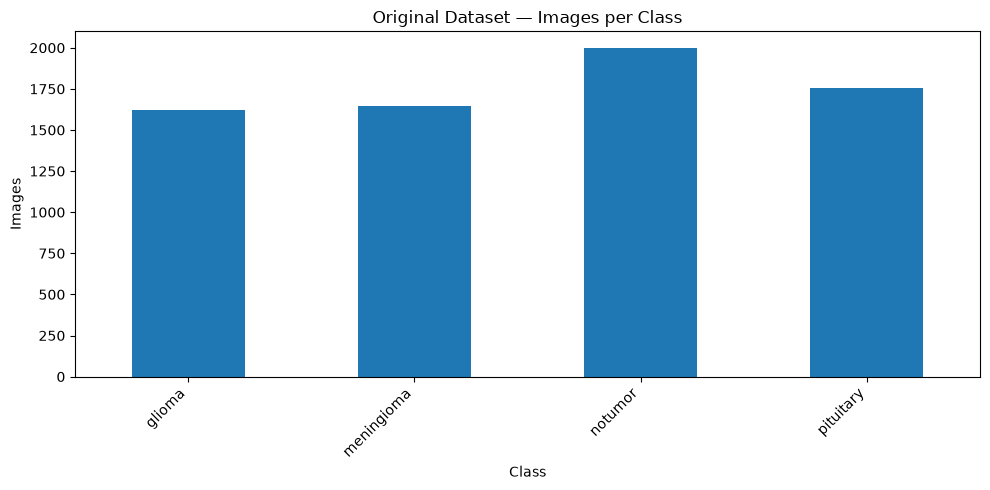

In [13]:
class_counts = df[LABEL_COL].value_counts().sort_index()
class_percentages = df[LABEL_COL].value_counts(normalize=True).sort_index() * 100
balance_report = pd.DataFrame({
    "image_count": class_counts,
    "percentage": class_percentages.round(2),
})
display(balance_report)

ax = class_counts.plot(kind="bar", figsize=(10, 5), title="Original Dataset — Images per Class")
ax.set_xlabel("Class")
ax.set_ylabel("Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "original_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

if (class_counts < 3).any():
    display(balance_report[balance_report["image_count"] < 3])
    raise ValueError(
        "At least one class has fewer than 3 samples. A 70/15/15 stratified split "
        "may not place that class in all splits. Review the data or choose a documented alternative."
    )


### 5. Create train, validation, and test splits
When PATIENT_COL is None, this performs two-stage stratified splitting. If a patient column is configured, it uses group splitting to keep each patient entirely within one split; group splitting may not preserve class proportions exactly, so inspect the next section. Patient-level separation takes priority over perfect stratification.

In [14]:
def split_by_patient(data: pd.DataFrame):
    """Group split to ensure a patient cannot occur in multiple splits."""
    if data[PATIENT_COL].isna().any() or data[PATIENT_COL].astype(str).str.strip().eq("").any():
        raise ValueError(f"{PATIENT_COL} contains missing/empty patient IDs.")
    groups = data[PATIENT_COL].astype(str)
    if groups.nunique() < 3:
        raise ValueError("Need at least 3 distinct patients for three disjoint splits.")

    # First 70% train, 30% temporary. GroupShuffleSplit proportions are approximate.
    first = GroupShuffleSplit(n_splits=1, train_size=TRAIN_RATIO, random_state=RANDOM_STATE)
    train_idx, temp_idx = next(first.split(data, groups=groups))
    train_part = data.iloc[train_idx].copy()
    temp_part = data.iloc[temp_idx].copy()

    # Split the temporary group set approximately in half.
    second = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=RANDOM_STATE + 1)
    val_rel_idx, test_rel_idx = next(second.split(temp_part, groups=temp_part[PATIENT_COL].astype(str)))
    val_part = temp_part.iloc[val_rel_idx].copy()
    test_part = temp_part.iloc[test_rel_idx].copy()
    return train_part, val_part, test_part

if PATIENT_COL is not None:
    train_df, validation_df, test_df = split_by_patient(df)
    split_method = "patient_grouped"
else:
    # Stratified image-level split: use only if images are independent across rows/patients.
    train_df, temporary_df = train_test_split(
        df,
        test_size=VALIDATION_RATIO + TEST_RATIO,
        random_state=RANDOM_STATE,
        stratify=df[LABEL_COL],
    )
    validation_df, test_df = train_test_split(
        temporary_df,
        test_size=TEST_RATIO / (VALIDATION_RATIO + TEST_RATIO),
        random_state=RANDOM_STATE + 1,
        stratify=temporary_df[LABEL_COL],
    )
    split_method = "stratified_image_level"

# Reset indices; keep original columns and the resolved path for integrity checks.
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

splits = {"train": train_df, "validation": validation_df, "test": test_df}
for name, split in splits.items():
    print(f"{name:10s}: {len(split):,} images ({len(split)/len(df):.2%})")
print("Method:", split_method)


train     : 4,916 images (70.00%)
validation: 1,053 images (14.99%)
test      : 1,054 images (15.01%)
Method: stratified_image_level


### 6. Compare class distribution across splits

,train,validation,test,original
label,,,,
notumor,1400,300,300,2000
pituitary,1230,263,264,1757
meningioma,1151,247,247,1645
glioma,1135,243,243,1621


,train,validation,test
label,,,
notumor,28.48,28.49,28.46
pituitary,25.02,24.98,25.05
meningioma,23.41,23.46,23.43
glioma,23.09,23.08,23.06


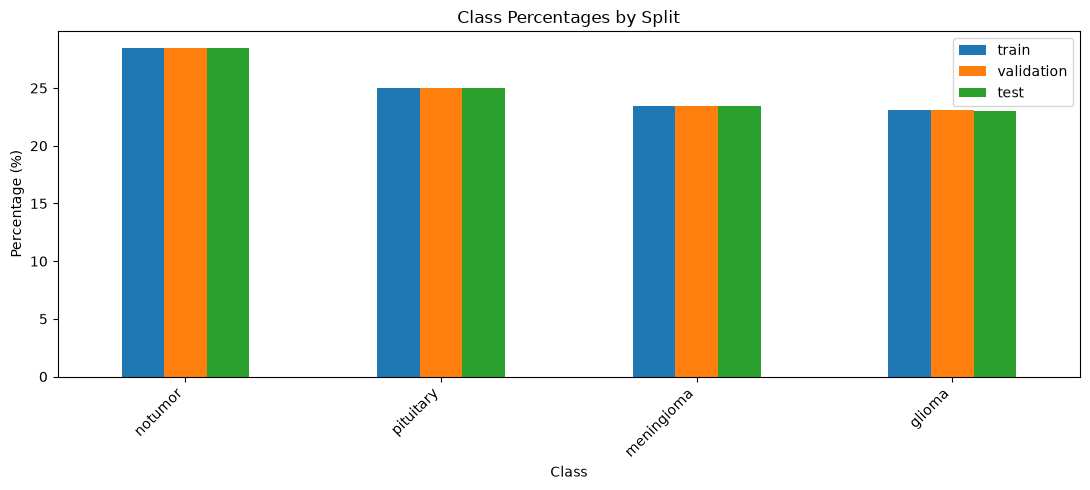

In [15]:
count_table = pd.DataFrame({
    name: split[LABEL_COL].value_counts() for name, split in splits.items()
}).fillna(0).astype(int)
count_table["original"] = df[LABEL_COL].value_counts().fillna(0).astype(int)
display(count_table)

percent_table = pd.DataFrame({
    name: split[LABEL_COL].value_counts(normalize=True) * 100
    for name, split in splits.items()
}).fillna(0)
display(percent_table.round(2))

ax = percent_table.plot(kind="bar", figsize=(11, 5), title="Class Percentages by Split")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "split_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


### 7. Verify split integrity and leakage

In [16]:
# Ensure every row is assigned exactly once.
assert len(train_df) + len(validation_df) + len(test_df) == len(df), "Sample count mismatch."

# Path overlap checks.
train_paths = set(train_df["_normalized_path"])
val_paths = set(validation_df["_normalized_path"])
test_paths = set(test_df["_normalized_path"])
assert train_paths.isdisjoint(val_paths), "Train/validation image overlap."
assert train_paths.isdisjoint(test_paths), "Train/test image overlap."
assert val_paths.isdisjoint(test_paths), "Validation/test image overlap."

# Confirm no path is lost or duplicated across the union.
all_split_paths = train_paths | val_paths | test_paths
assert all_split_paths == set(df["_normalized_path"]), "Some image paths were lost or added."

# Patient leakage checks, if a patient column is configured.
if PATIENT_COL is not None:
    train_patients = set(train_df[PATIENT_COL].astype(str))
    val_patients = set(validation_df[PATIENT_COL].astype(str))
    test_patients = set(test_df[PATIENT_COL].astype(str))
    assert train_patients.isdisjoint(val_patients), "Patient leakage: train/validation."
    assert train_patients.isdisjoint(test_patients), "Patient leakage: train/test."
    assert val_patients.isdisjoint(test_patients), "Patient leakage: validation/test."
    print("Patient-level leakage checks passed.")

# Verify the files still exist.
for name, split in splits.items():
    missing = ~split["_resolved_path"].map(Path.is_file)
    assert not missing.any(), f"Missing image file(s) in {name}."

# Every class should appear in each split for a normal stratified setup.
all_classes = set(df[LABEL_COL].astype(str))
for name, split in splits.items():
    missing_classes = all_classes - set(split[LABEL_COL].astype(str))
    if missing_classes:
        warnings.warn(f"{name} is missing classes: {sorted(missing_classes)}")
    else:
        print(f"{name}: all classes represented")

print("All critical path/sample integrity checks passed.")


train: all classes represented
validation: all classes represented
test: all classes represented
All critical path/sample integrity checks passed.


### 8. Export the split manifests and summary report
Helper columns beginning with _ are internal and are not exported. All source columns—including annotation columns, if present—are preserved.

In [17]:
def exportable_columns(data: pd.DataFrame):
    return [col for col in data.columns if not col.startswith("_")]

for name, split in splits.items():
    destination = OUTPUT_DIR / f"{name}.csv"
    split[exportable_columns(split)].to_csv(destination, index=False)
    print("Saved:", destination)

summary = {
    "random_state": RANDOM_STATE,
    "split_method": split_method,
    "requested_ratios": {
        "train": TRAIN_RATIO,
        "validation": VALIDATION_RATIO,
        "test": TEST_RATIO,
    },
    "total_samples": int(len(df)),
    "actual_split_sizes": {name: int(len(split)) for name, split in splits.items()},
    "actual_split_percentages": {name: round(len(split) / len(df) * 100, 4) for name, split in splits.items()},
    "label_column": LABEL_COL,
    "patient_column": PATIENT_COL,
    "class_counts": {
        name: {str(k): int(v) for k, v in split[LABEL_COL].value_counts().items()}
        for name, split in splits.items()
    },
    "integrity_checks": {
        "sample_count_matches": True,
        "image_path_overlap": False,
        "all_paths_exist": True,
        "patient_leakage_checked": PATIENT_COL is not None,
    },
}
summary_path = OUTPUT_DIR / "split_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved:", summary_path)


Saved: /home/moali/projects/brainscan_ai/data/splits/train.csv
Saved: /home/moali/projects/brainscan_ai/data/splits/validation.csv
Saved: /home/moali/projects/brainscan_ai/data/splits/test.csv
Saved: /home/moali/projects/brainscan_ai/data/splits/split_summary.json


### 9. Final report

In [18]:
final_report = pd.DataFrame([
    {
        "split": name,
        "samples": len(split),
        "actual_percentage": round(len(split) / len(df) * 100, 2),
        "classes_present": split[LABEL_COL].nunique(),
        "unique_patients": split[PATIENT_COL].nunique() if PATIENT_COL else None,
    }
    for name, split in splits.items()
])
display(final_report)

print(f"Original samples: {len(df):,}")
print(f"Exported samples: {sum(len(s) for s in splits.values()):,}")
print("Split method:", split_method)
print("Output directory:", OUTPUT_DIR.resolve())
print("Next: use train.csv for training, validation.csv for model selection, and test.csv only for final evaluation.")


,split,samples,actual_percentage,classes_present,unique_patients
0,train,4916,70.00,4,None
1,validation,1053,14.99,4,None
2,test,1054,15.01,4,None


Original samples: 7,023
Exported samples: 7,023
Split method: stratified_image_level
Output directory: /home/moali/projects/brainscan_ai/data/splits
Next: use train.csv for training, validation.csv for model selection, and test.csv only for final evaluation.
